In [1]:
import numpy as np
import matplotlib.pyplot as plt 
import cv2

In [3]:
def plot_image(image_1, image_2,title_1="Orignal", title_2="New Image"):
    plt.figure(figsize=(10,10))
    plt.subplot(1,2,1)
    plt.imshow(image_1, cmap="gray")
    plt.title(title_1)
    plt.subplot(1,2,2)
    plt.imshow(image_2, cmap="gray")
    plt.title(title_2)
    plt.show()

In [4]:
def plot_histogram(old_image, new_image, title_old="Original", title_new="New Image"):
    intensity_values=np.array([x for x in range(256)])
    plt.subplot(1,2,1)
    plt.bar(intensity_values, cv2.calcHist([old_image],[0],None,[256],[0,256]) [:,0],width= 5)
    plt.title(title_old)
    plt.xlabel("Intensity")
    plt.subplot(1,2,2)
    plt.bar(intensity_values, cv2.calcHist([new_image],[0],None,[256],[0,256]) [:,0],width= 5)
    plt.title(title_new)
    plt.xlabel("Intensity")
    plt.show()

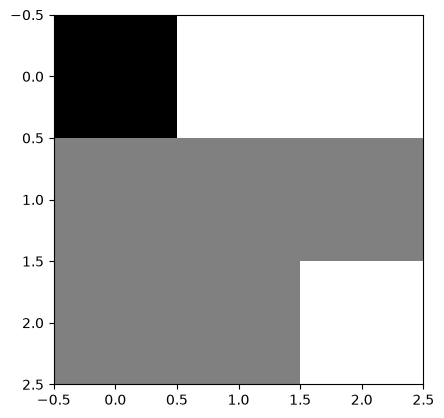

Toy Image: [[0 2 2]
 [1 1 1]
 [1 1 2]]


In [5]:
toy_image = np.array([[0,2,2], [1,1,1], [1,1,2]],dtype=np.uint8)
plt.imshow(toy_image, cmap="gray")
plt.show()
print("Toy Image:", toy_image)

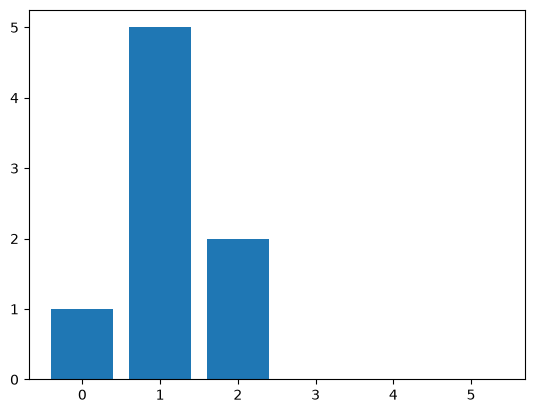

In [6]:
plt.bar([X for X in range(6)], [1,5,2,0,0,0])
plt.show()

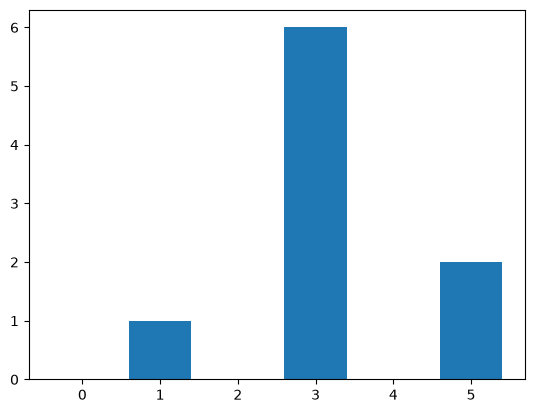

In [10]:
plt.bar([X for X in range(6)],[0,1,0,6,0,2])
plt.show()

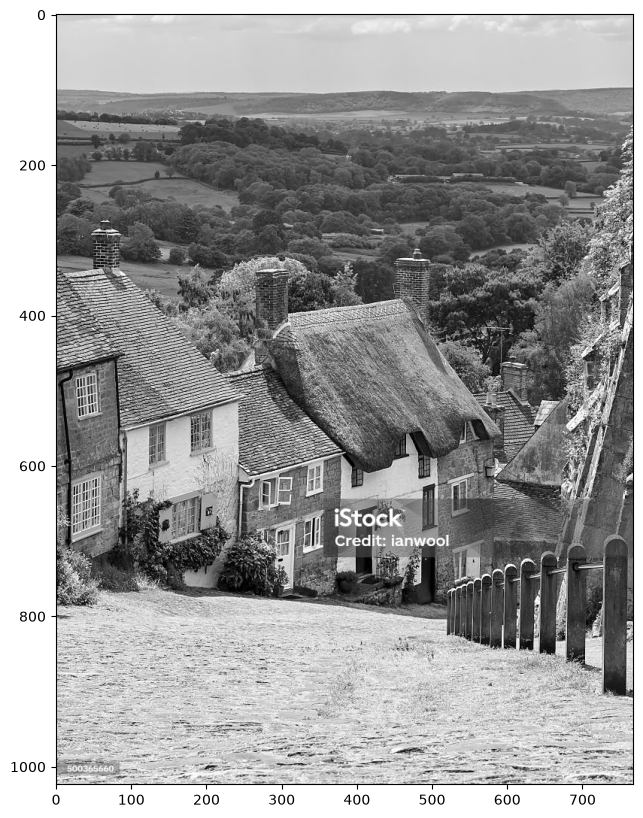

In [14]:
goldhill = cv2.imread("goldhill.jpg", cv2.IMREAD_GRAYSCALE)
plt.figure(figsize=(10, 10))
plt.imshow(goldhill, cmap="gray")
plt.show()

In [15]:
hist = cv2.calcHist([goldhill],[0],None,[256],[0,256])

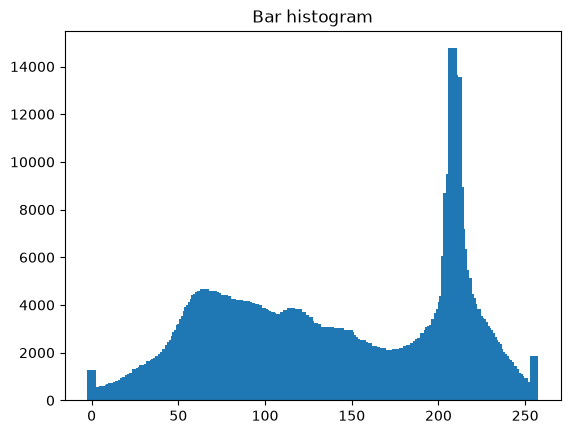

In [26]:
intensity_values=np.array([x for x in range(hist.shape[0])])
plt.bar(intensity_values, hist, width= 5)
plt.title("Bar histogram")
plt.show()

In [27]:
PMF = hist  / (goldhill.shape[0] * goldhill.shape[1])

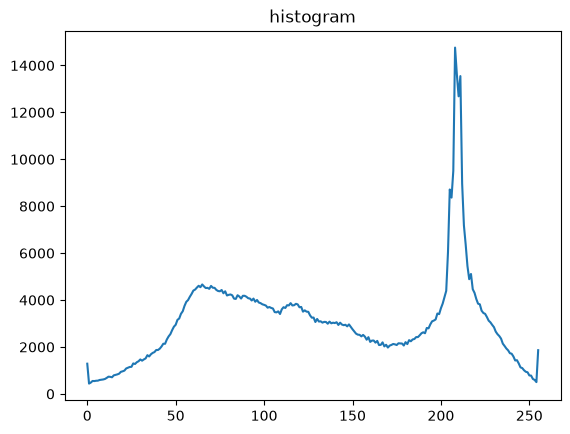

In [28]:
plt.plot(intensity_values, hist)
plt.title("histogram")
plt.show()

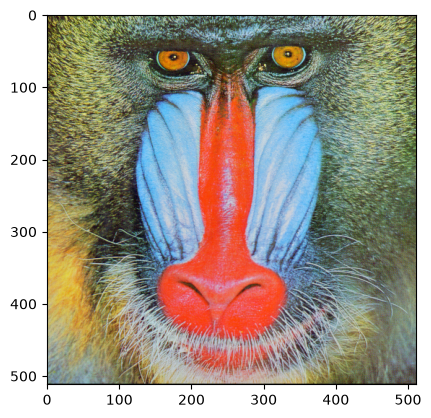

In [29]:
baboon = cv2.imread("baboon.png")
plt.imshow(cv2.cvtColor(baboon, cv2.COLOR_BGR2RGB))
plt.show()

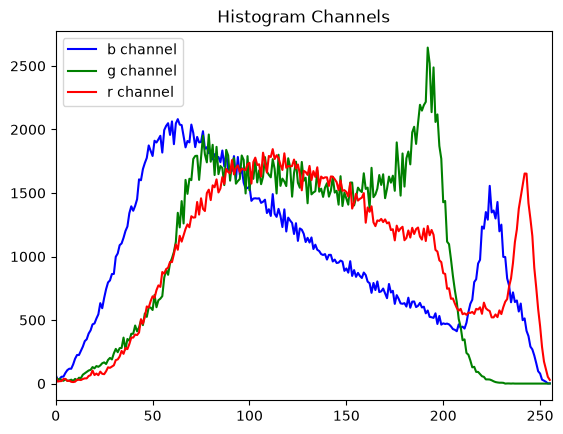

In [30]:
color = ("b", "g", "r")
for i,col in enumerate(color):
    hist = cv2.calcHist([baboon],[i],None,[256],[0,256])
    plt.plot(intensity_values,hist,color = col,label=col+" channel")

    plt.xlim([0,256])
plt.legend()
plt.title("Histogram Channels")
plt.show()

In [31]:
neg_toy_image = 255 - toy_image

print("toy image\n", toy_image)
print("negative toy image\n", neg_toy_image)
print("image negative\n", neg_toy_image)

toy image
 [[0 2 2]
 [1 1 1]
 [1 1 2]]
negative toy image
 [[255 253 253]
 [254 254 254]
 [254 254 253]]
image negative
 [[255 253 253]
 [254 254 254]
 [254 254 253]]


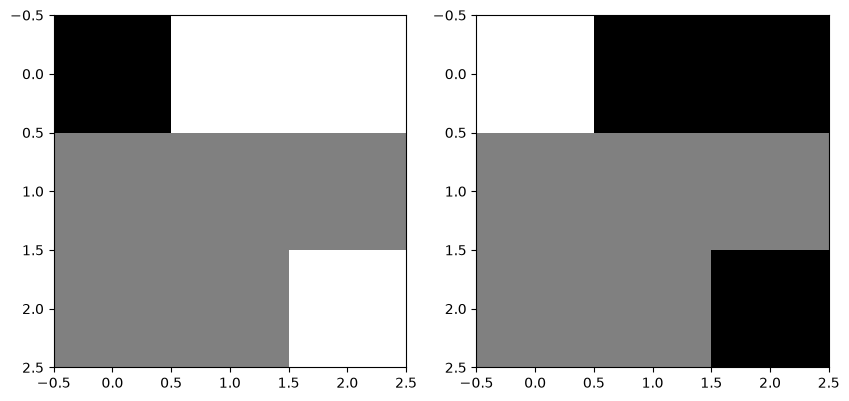

toy_image: [[0 2 2]
 [1 1 1]
 [1 1 2]]


In [32]:
plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.imshow(toy_image, cmap="gray")
plt.subplot(1,2,2)
plt.imshow(neg_toy_image, cmap="gray")
plt.show()
print("toy_image:",toy_image)

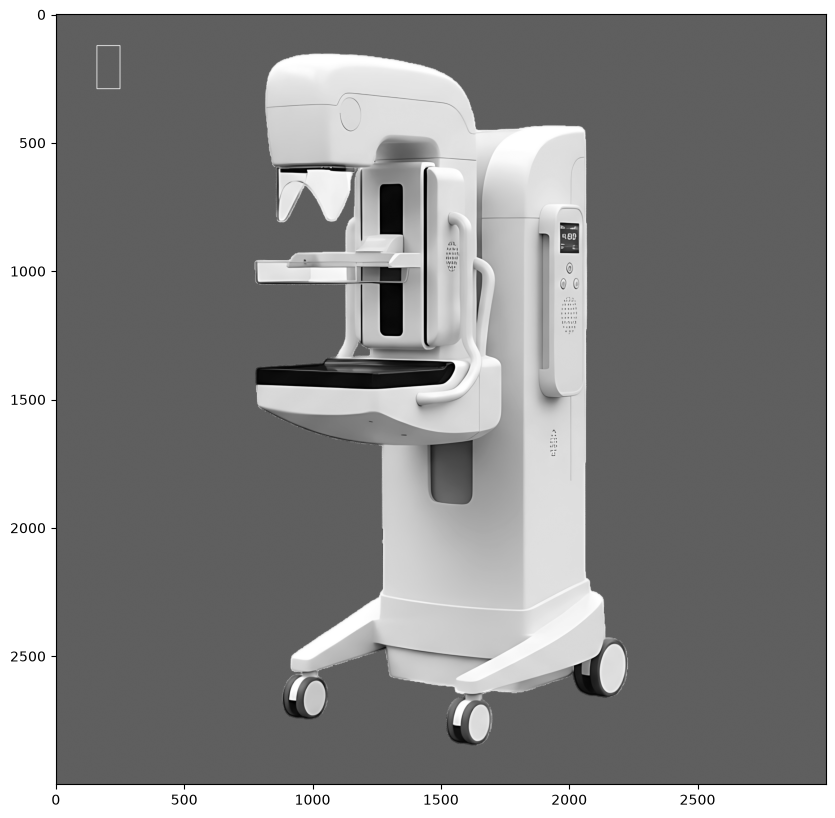

In [33]:
image = cv2.imread("mammogram.png", cv2.IMREAD_GRAYSCALE)
cv2.rectangle(image, pt1=(160,121), pt2=(250, 289), color=(255), thickness=2)

plt.figure(figsize=(10,10))
plt.imshow(image, cmap="gray")
plt.show()

In [34]:
img_neg = 255 -image

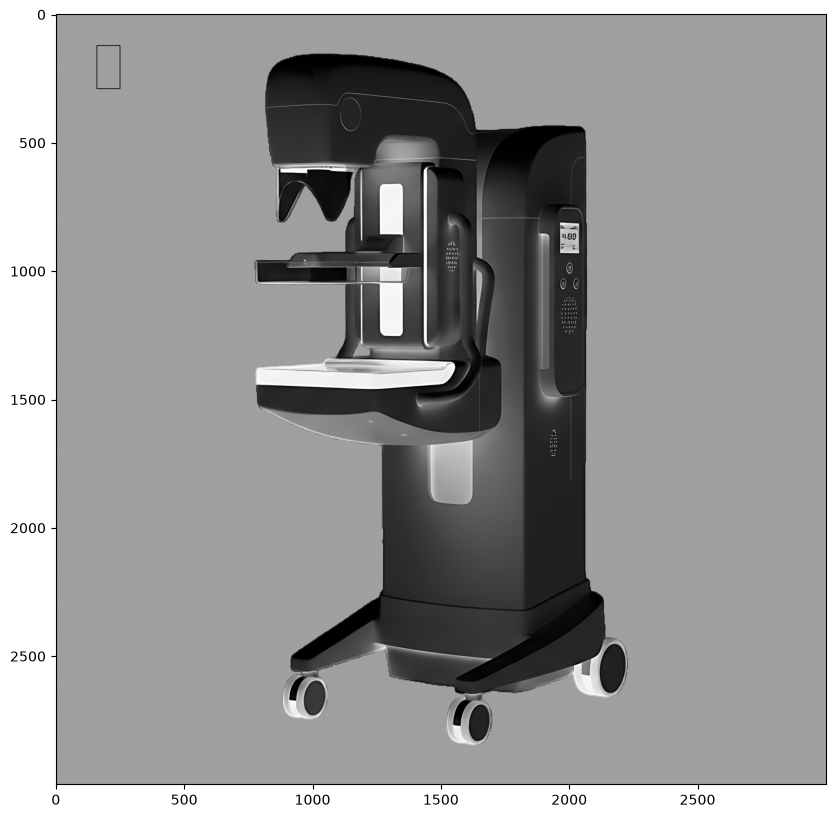

In [35]:
plt.figure(figsize=(10,10))
plt.imshow(img_neg, cmap="gray")
plt.show()

In [36]:
alpha = 1 #Simple contrast control
beta = 0 #Simple brightness control
new_image = cv2.convertScaleAbs(goldhill, alpha=alpha, beta=beta)


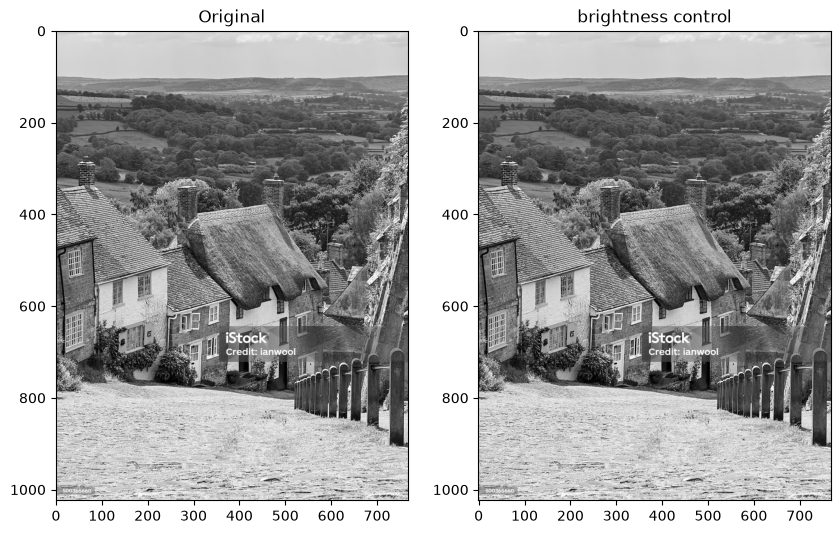

In [37]:
plot_image(goldhill, new_image, title_1 = "Original", title_2 = "brightness control
")

In [45]:
plt.figure(figsize=(10,5))
plot_hist(goldhill, new_image, "Original", "contrast control")

NameError: name 'plot_hist' is not defined

<Figure size 1000x1000 with 0 Axes>

In [43]:
import matplotlib.pyplot as plt

In [46]:
plt.figure(figsize=(10,5))
alpha = 2#Simple contrast control
beta = 0 # Simple brightness control # Simpple brightness control
new_image = cv2.convertScaleAbs(goldhill, alpha=alpha, beta=beta)

<Figure size 1000x500 with 0 Axes>

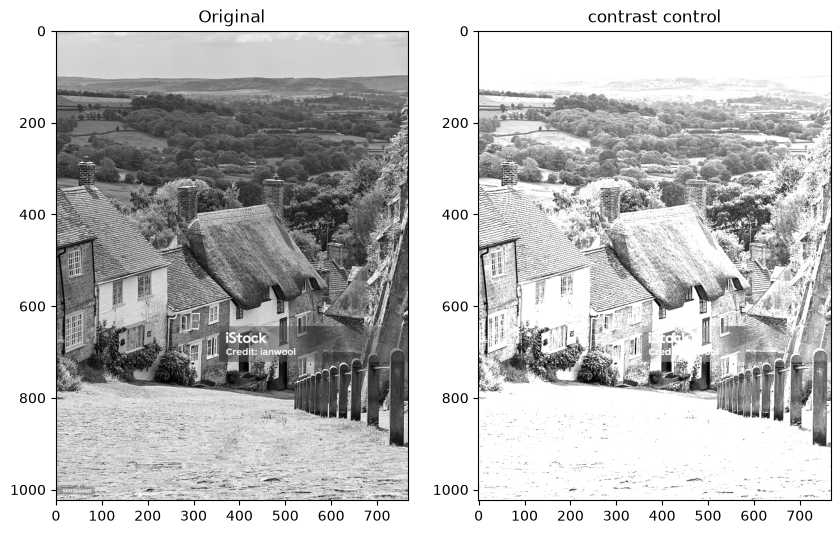

In [48]:
plot_image(goldhill, new_image, "Original", "contrast control")

IndexError: too many indices for array: array is 1-dimensional, but 2 were indexed

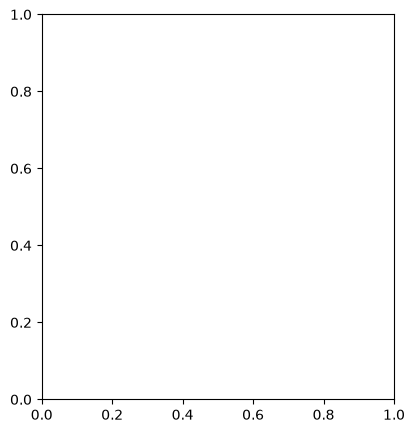

In [55]:
plt.figure(figsize=(10,5))
plot_histogram(goldhill, new_image, "Original", "brightness control")

In [57]:
plt.figure(figsize=(10,5))
alpha = 2# Simple contrast control
beta = 0 # Simple brightness control # Simple brightness control
new_image = cv2.convertScaleAbs(goldhill, alpha=alpha, beta=beta)

<Figure size 1000x500 with 0 Axes>

In [58]:
zelda = cv2.imread("zelda.jpg", cv2.IMREAD_GRAYSCALE)
new_image = cv2.equalizeHist(zelda)

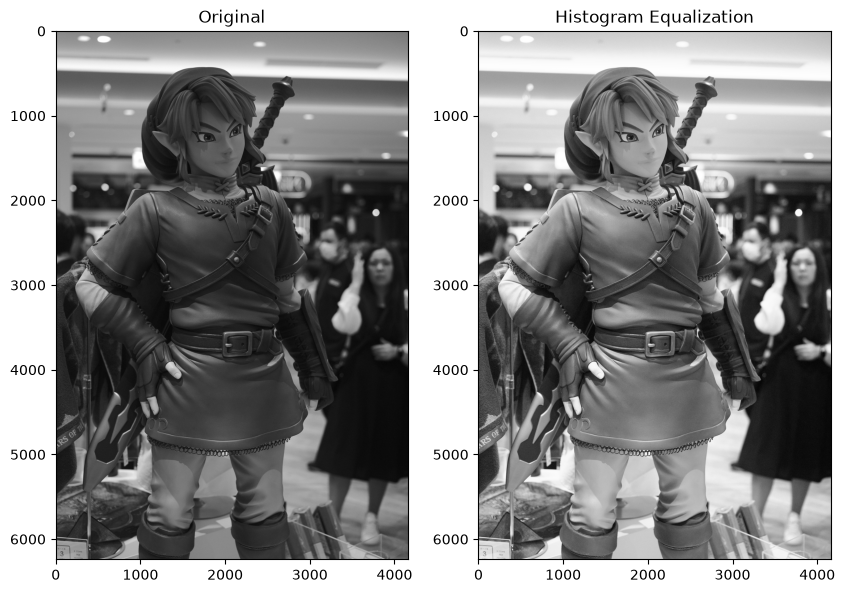

In [60]:
plot_image(zelda, new_image, "Original", "Histogram Equalization")

In [61]:
plt.figure(figsize=(10,5))
plot_hist(zelda, new_image,"Original", "Histogram Equalization")

NameError: name 'plot_hist' is not defined

<Figure size 1000x500 with 0 Axes>

In [62]:
def thresholding(input_image, threshold,max_value=255, min_value=0):
    N,M=input_image.shape
    image_out=np.zeros((N,M), dtype=np.uint8)


    for i in range(N):
        for j in range(M):
            if input_image[i,j] > threshold:
                image_out[i,j] = max_value
            else:
                image_out[i,j] = min_value

    return image_out

In [63]:
toy_image

array([[0, 2, 2],
       [1, 1, 1],
       [1, 1, 2]], dtype=uint8)

In [69]:
threhold = 1
max_value = 2
min_value = 0
thresholding_toy = thresholding(toy_image, threshold=threshold, max_value=max_value, min_value=min_value)
thresholding_toy

NameError: name 'threshold' is not defined

NameError: name 'thresholding_toy' is not defined

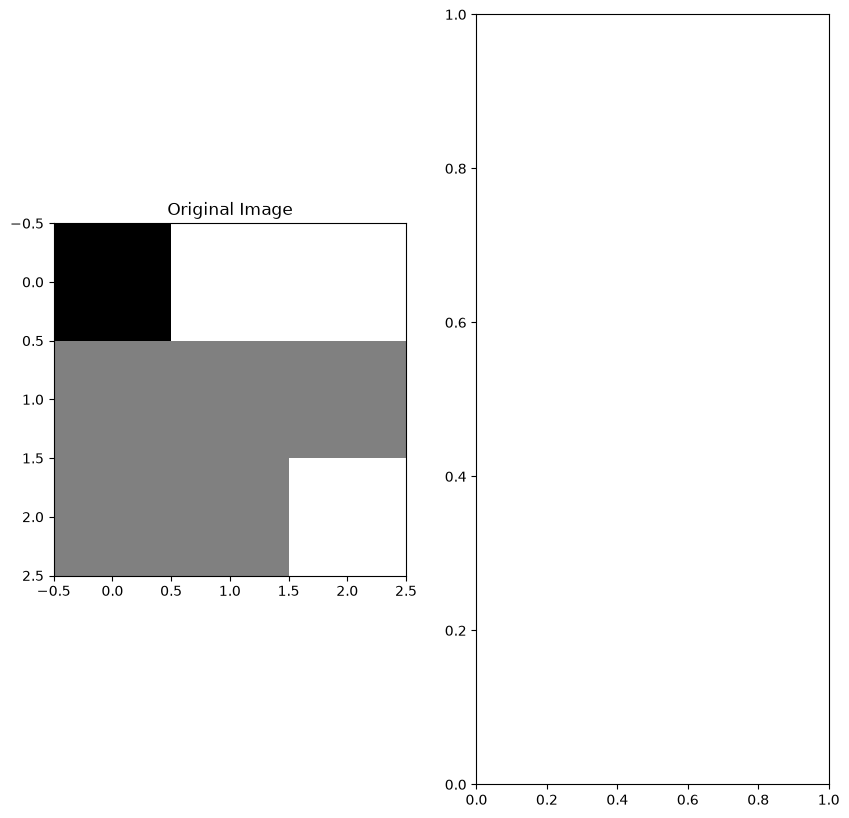

In [72]:
plt.figure(figsize=(10,10))
plt.subplot(1,2,1)
plt.imshow(toy_image, cmap="gray")
plt.title("Original Image")
plt.subplot(1,2,2)
plt.imshow(thresholding_toy, cmap="gray")
plt.title("Image After Thresholding")
plt.show

TypeError: Image data of dtype object cannot be converted to float

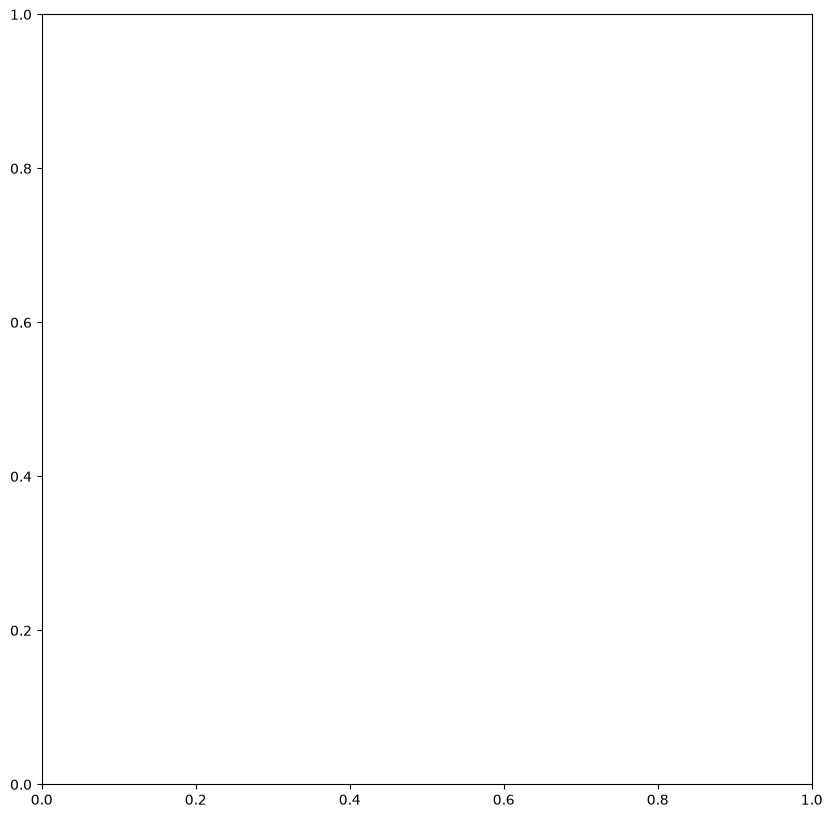

In [76]:
image = cv2.imread("cameraman.jpg", cv2.IMREAD_GRAYSCALE)
plt.figure(figsize=(10,10))
plt.imshow(image, cmap="gray")
plt.show()